<a href="https://colab.research.google.com/github/KamilMleczko/TrzymamNotatniki/blob/main/Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Loading MNIST dataset...

Training models and measuring time...
Logistic Regression       | Time: 10.1380s | Accuracy: 0.8995
Decision Tree             | Time: 2.4143s | Accuracy: 0.8245
Neural Network (MLP)      | Time: 12.6319s | Accuracy: 0.9490


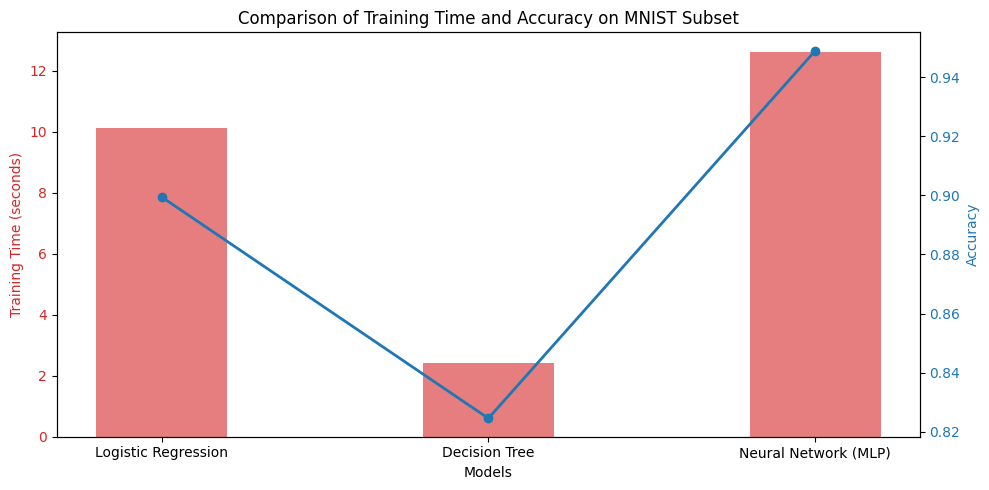

In [1]:
import time
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

# 1. Load a subset of MNIST dataset for exemplary/fast execution
print("Loading MNIST dataset...")
X, y = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False)

# Using a subset (e.g., 10,000 samples) to keep training times reasonable for demonstration
X_subset, y_subset = X[:10000], y[:10000]

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_subset)

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_subset, test_size=0.2, random_state=42
)

# Define the models
models = {
    "Logistic Regression": LogisticRegression(max_iter=150, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Neural Network (MLP)": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=150, random_state=42)
}

# Dictionary to store results
results = {}

# 2. Train models and measure training time
print("\nTraining models and measuring time...")
for name, model in models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    elapsed_time = time.time() - start_time

    # Evaluate accuracy
    accuracy = model.score(X_test, y_test)

    results[name] = {
        "Training Time (s)": elapsed_time,
        "Accuracy": accuracy
    }
    print(f"{name:25} | Time: {elapsed_time:.4f}s | Accuracy: {accuracy:.4f}")

# 3. Simple visualization of the comparison
names = list(results.keys())
times = [results[name]["Training Time (s)"] for name in names]
accuracies = [results[name]["Accuracy"] for name in names]

fig, ax1 = plt.subplots(figsize=(10, 5))

# Plot Training Time
color = 'tab:red'
ax1.set_xlabel('Models')
ax1.set_ylabel('Training Time (seconds)', color=color)
bars = ax1.bar(names, times, color=color, alpha=0.6, width=0.4, label='Training Time')
ax1.tick_params(axis='y', labelcolor=color)

# Plot Accuracy on a secondary axis
ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Accuracy', color=color)
ax2.plot(names, accuracies, color=color, marker='o', linewidth=2, label='Accuracy')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Comparison of Training Time and Accuracy on MNIST Subset')
fig.tight_layout()
plt.show()